**Experiment-7: Text Classification using Deep Learning Models**

Using device: cpu
Dataset loaded successfully!
Dataset Shape: (45999, 2)
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               

Epoch 1/3:   0%|          | 0/5 [00:00<?, ?it/s]

Epoch 1 Average Loss: 0.6899


Epoch 2/3:   0%|          | 0/5 [00:00<?, ?it/s]

Epoch 2 Average Loss: 0.6605


Epoch 3/3:   0%|          | 0/5 [00:00<?, ?it/s]

... (19 outputs left out)

BERT Epoch 2/2:   0%|          | 0/18 [00:00<?, ?it/s]

BERT Epoch 2 Average Loss: 0.6444


BERT Testing:   0%|          | 0/5 [00:00<?, ?it/s]


BERT

Accuracy: 0.5775
Precision: 0.569
Recall: 0.8684
F1 Score: 0.6875

Classification Report:
              precision    recall  f1-score   support

    Negative       0.62      0.24      0.35        33
    Positive       0.57      0.87      0.69        38

    accuracy                           0.58        71
   macro avg       0.59      0.56      0.52        71
weighted avg       0.59      0.58      0.53        71


FINAL MODEL COMPARISON
                     Accuracy  Precision  Recall  F1 Score
LSTM                   0.6338     0.6000  0.9474    0.7347
Vanilla Transformer    0.5352     0.5352  1.0000    0.6972
BERT                   0.5775     0.5690  0.8684    0.6875
Logistic Regression    0.5493     0.5652  0.6842    0.6190


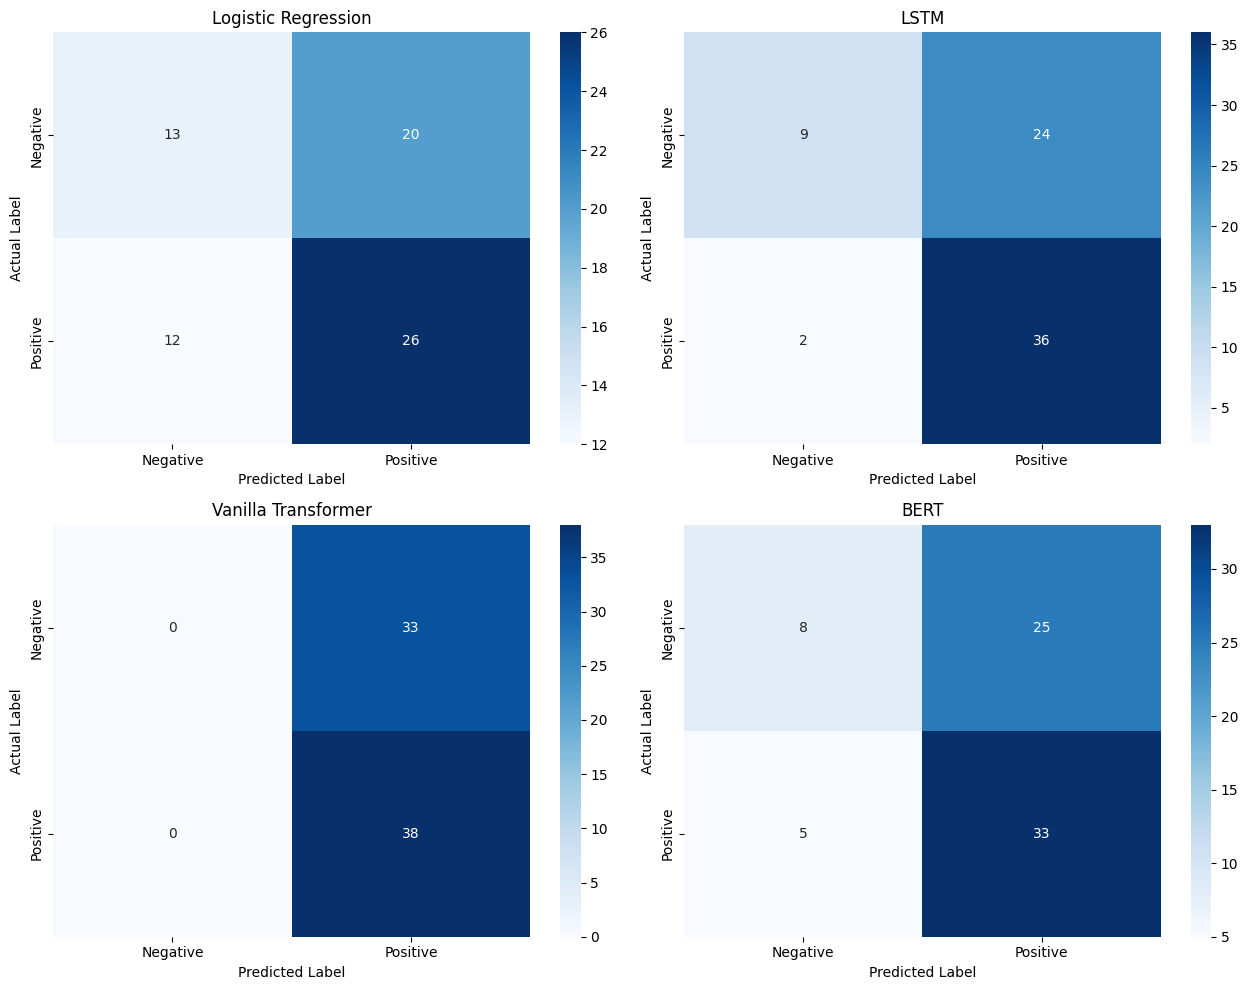

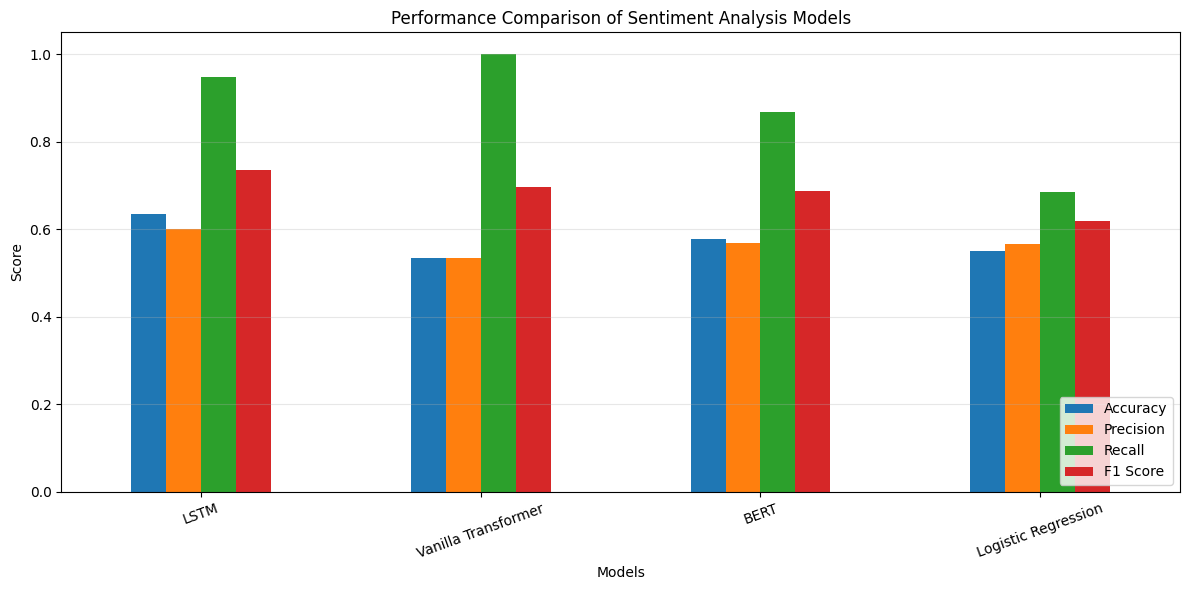


Best Performing Model: LSTM
Best F1 Score: 0.7347

Experiment Completed Successfully!
Generated Files:
1. IMDB_Model_Comparison.csv
2. IMDB_Final_Results.csv
3. IMDB_Confusion_Matrices.png
4. IMDB_Performance_Comparison.png


In [5]:
# Sentiment Analysis on IMDB Movie Reviews
# Logistic Regression, LSTM, Vanilla Transformer and BERT

# Import Libraries

import re
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import csv

from collections import Counter
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from tqdm.auto import tqdm


# Set Random Seeds

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


# Load IMDB Dataset

file_path = "IMDB Dataset.csv"

if not os.path.exists(file_path):
    file_path = "/content/IMDB Dataset.csv"

# Load IMDB Dataset safely

df = pd.read_csv(
    file_path,
    engine="python",
    on_bad_lines="skip",
    encoding="utf-8",
    quoting=csv.QUOTE_NONE
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
print(df.head())
print(df.columns)

print("\nDataset Shape:", df.shape)
print("\nDataset Columns:")
print(df.columns)

print("\nFirst Five Rows:")
print(df.head())

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())


# Remove Missing Values and Duplicates

df = df.dropna(subset=["review", "sentiment"])

df["review"] = df["review"].astype(str)

df["sentiment"] = df["sentiment"].str.lower().str.strip()

df = df[df["sentiment"].isin(["positive", "negative"])]

df = df.drop_duplicates(subset=["review"])

df["label"] = df["sentiment"].map({
    "positive": 1,
    "negative": 0
})

print("\nCleaned Dataset Shape:", df.shape)


# Text Preprocessing

def clean_text(text):

    text = text.lower()

    text = re.sub(r"<br\s*/?>", " ", text)

    text = re.sub(r"<[^>]+>", " ", text)

    text = re.sub(r"[^a-z0-9\s']", " ", text)

    text = re.sub(r"\s+", " ", text).strip()

    return text


df["clean_review"] = df["review"].apply(clean_text)

X = df["clean_review"].values
y = df["label"].values


# Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


# Store Results

results = {}
predictions = {}


# Evaluation Function

def evaluate_model(model_name, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true, y_pred, zero_division=0
    )

    recall = recall_score(
        y_true, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred, zero_division=0
    )

    results[model_name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }

    predictions[model_name] = y_pred

    print("\n", "=" * 50)
    print(model_name)
    print("=" * 50)

    print("\nAccuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))

    print("\nClassification Report:")

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=["Negative", "Positive"],
            zero_division=0
        )
    )


# ==========================================================
# LOGISTIC REGRESSION
# ==========================================================

print("\nTraining Logistic Regression...")


# Convert Text into TF-IDF Features

tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)


# Train Logistic Regression

logistic_model = LogisticRegression(
    max_iter=1000,
    C=2.0,
    solver="liblinear",
    random_state=SEED
)

logistic_model.fit(X_train_tfidf, y_train)


# Predict Sentiment

lr_predictions = logistic_model.predict(X_test_tfidf)


# Evaluate Logistic Regression

evaluate_model(
    "Logistic Regression",
    y_test,
    lr_predictions
)


# ==========================================================
# TOKENIZATION FOR LSTM AND VANILLA TRANSFORMER
# ==========================================================

print("\nPreparing Tokenized Dataset...")


# Build Vocabulary Using Training Data Only

MAX_VOCAB = 30000
MAX_LEN = 200

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

counter = Counter()

for review in X_train:

    counter.update(review.split())

vocab = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

for word, count in counter.most_common(MAX_VOCAB - 2):

    vocab[word] = len(vocab)

vocab_size = len(vocab)

print("Vocabulary Size:", vocab_size)


# Convert Reviews into Numerical Sequences

def encode_review(review):

    tokens = review.split()

    ids = [
        vocab.get(word, vocab[UNK_TOKEN])
        for word in tokens[:MAX_LEN]
    ]

    if len(ids) < MAX_LEN:

        ids += [vocab[PAD_TOKEN]] * (
            MAX_LEN - len(ids)
        )

    return ids


X_train_seq = np.array(
    [encode_review(text) for text in X_train],
    dtype=np.int64
)

X_test_seq = np.array(
    [encode_review(text) for text in X_test],
    dtype=np.int64
)


# Create PyTorch Datasets

train_dataset = TensorDataset(
    torch.tensor(X_train_seq, dtype=torch.long),
    torch.tensor(y_train, dtype=torch.float32)
)

test_dataset = TensorDataset(
    torch.tensor(X_test_seq, dtype=torch.long),
    torch.tensor(y_test, dtype=torch.float32)
)

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


# ==========================================================
# COMMON TRAINING AND PREDICTION FUNCTIONS
# ==========================================================

def train_neural_model(model, train_loader, epochs, lr):

    model = model.to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr
    )

    criterion = nn.BCEWithLogitsLoss()

    for epoch in range(epochs):

        model.train()

        total_loss = 0

        progress = tqdm(
            train_loader,
            desc=f"Epoch {epoch + 1}/{epochs}"
        )

        for inputs, labels in progress:

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)

            loss = criterion(
                outputs.squeeze(1),
                labels
            )

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

            progress.set_postfix(
                loss=loss.item()
            )

        avg_loss = total_loss / len(train_loader)

        print(
            f"Epoch {epoch + 1} Average Loss: "
            f"{avg_loss:.4f}"
        )

    return model


def get_predictions(model, loader):

    model.eval()

    all_predictions = []

    with torch.no_grad():

        for inputs, labels in loader:

            inputs = inputs.to(device)

            outputs = model(inputs)

            probabilities = torch.sigmoid(
                outputs.squeeze(1)
            )

            predicted = (
                probabilities >= 0.5
            ).long()

            all_predictions.extend(
                predicted.cpu().numpy()
            )

    return np.array(all_predictions)


# ==========================================================
# LSTM MODEL
# ==========================================================

print("\nTraining LSTM Model...")


class LSTMModel(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(0.3)

        self.fc = nn.Linear(
            hidden_dim * 2,
            1
        )

    def forward(self, x):

        embedded = self.embedding(x)

        output, (hidden, cell) = self.lstm(
            embedded
        )

        forward_hidden = hidden[-2]

        backward_hidden = hidden[-1]

        combined = torch.cat(
            (forward_hidden, backward_hidden),
            dim=1
        )

        combined = self.dropout(combined)

        return self.fc(combined)


# Initialize LSTM

lstm_model = LSTMModel(vocab_size)


# Train LSTM

lstm_model = train_neural_model(
    lstm_model,
    train_loader,
    epochs=3,
    lr=0.001
)


# Predict Using LSTM

lstm_predictions = get_predictions(
    lstm_model,
    test_loader
)


# Evaluate LSTM

evaluate_model(
    "LSTM",
    y_test,
    lstm_predictions
)


# ==========================================================
# VANILLA TRANSFORMER MODEL
# ==========================================================

print("\nTraining Vanilla Transformer...")


class PositionalEncoding(nn.Module):

    def __init__(self, embedding_dim, max_len=200):

        super().__init__()

        position = torch.arange(
            max_len
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, embedding_dim, 2)
            * (-np.log(10000.0) / embedding_dim)
        )

        pe = torch.zeros(
            max_len,
            embedding_dim
        )

        pe[:, 0::2] = torch.sin(
            position * div_term
        )

        pe[:, 1::2] = torch.cos(
            position * div_term[:pe[:, 1::2].shape[1]]
        )

        self.register_buffer(
            "pe",
            pe.unsqueeze(0)
        )

    def forward(self, x):

        return x + self.pe[:, :x.size(1)]


class VanillaTransformer(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        num_heads=4,
        num_layers=2
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.position = PositionalEncoding(
            embedding_dim,
            MAX_LEN
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim,
            nhead=num_heads,
            dim_feedforward=256,
            dropout=0.2,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.dropout = nn.Dropout(0.3)

        self.fc = nn.Linear(
            embedding_dim,
            1
        )

    def forward(self, x):

        padding_mask = (x == 0)

        embedded = self.embedding(x)

        embedded = self.position(embedded)

        encoded = self.transformer(
            embedded,
            src_key_padding_mask=padding_mask
        )

        mask = (~padding_mask).unsqueeze(-1)

        pooled = (
            encoded * mask
        ).sum(dim=1) / mask.sum(
            dim=1
        ).clamp(min=1)

        pooled = self.dropout(pooled)

        return self.fc(pooled)


# Initialize Transformer

transformer_model = VanillaTransformer(
    vocab_size=vocab_size
)


# Train Transformer

transformer_model = train_neural_model(
    transformer_model,
    train_loader,
    epochs=3,
    lr=0.0005
)


# Predict Using Transformer

transformer_predictions = get_predictions(
    transformer_model,
    test_loader
)


# Evaluate Transformer

evaluate_model(
    "Vanilla Transformer",
    y_test,
    transformer_predictions
)


# ==========================================================
# PRETRAINED BERT MODEL
# ==========================================================

print("\nLoading Pretrained BERT Model...")


BERT_NAME = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(
    BERT_NAME
)

bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_NAME,
    num_labels=2
)

bert_model = bert_model.to(device)


# Tokenize Reviews

MAX_BERT_LEN = 256

train_encodings = bert_tokenizer(
    list(X_train),
    truncation=True,
    padding="max_length",
    max_length=MAX_BERT_LEN,
    return_tensors="pt"
)

test_encodings = bert_tokenizer(
    list(X_test),
    truncation=True,
    padding="max_length",
    max_length=MAX_BERT_LEN,
    return_tensors="pt"
)


# Create BERT Datasets

bert_train_dataset = TensorDataset(
    train_encodings["input_ids"],
    train_encodings["attention_mask"],
    torch.tensor(y_train, dtype=torch.long)
)

bert_test_dataset = TensorDataset(
    test_encodings["input_ids"],
    test_encodings["attention_mask"],
    torch.tensor(y_test, dtype=torch.long)
)

BERT_BATCH_SIZE = 16

bert_train_loader = DataLoader(
    bert_train_dataset,
    batch_size=BERT_BATCH_SIZE,
    shuffle=True
)

bert_test_loader = DataLoader(
    bert_test_dataset,
    batch_size=BERT_BATCH_SIZE,
    shuffle=False
)


# Fine-Tune BERT

print("\nFine-Tuning BERT...")

bert_optimizer = torch.optim.AdamW(
    bert_model.parameters(),
    lr=2e-5
)

BERT_EPOCHS = 2

for epoch in range(BERT_EPOCHS):

    bert_model.train()

    total_loss = 0

    progress = tqdm(
        bert_train_loader,
        desc=f"BERT Epoch {epoch + 1}/{BERT_EPOCHS}"
    )

    for input_ids, attention_mask, labels in progress:

        input_ids = input_ids.to(device)

        attention_mask = attention_mask.to(device)

        labels = labels.to(device)

        bert_optimizer.zero_grad()

        outputs = bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        loss.backward()

        bert_optimizer.step()

        total_loss += loss.item()

        progress.set_postfix(
            loss=loss.item()
        )

    print(
        f"BERT Epoch {epoch + 1} Average Loss: "
        f"{total_loss / len(bert_train_loader):.4f}"
    )


# Predict Using BERT

bert_model.eval()

bert_predictions = []

with torch.no_grad():

    for input_ids, attention_mask, labels in tqdm(
        bert_test_loader,
        desc="BERT Testing"
    ):

        input_ids = input_ids.to(device)

        attention_mask = attention_mask.to(device)

        outputs = bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predicted = torch.argmax(
            outputs.logits,
            dim=1
        )

        bert_predictions.extend(
            predicted.cpu().numpy()
        )


bert_predictions = np.array(bert_predictions)


# Evaluate BERT

evaluate_model(
    "BERT",
    y_test,
    bert_predictions
)


# ==========================================================
# COMPARATIVE ANALYSIS
# ==========================================================

print("\nFINAL MODEL COMPARISON")


comparison_df = pd.DataFrame(
    results
).T

comparison_df = comparison_df.sort_values(
    by="F1 Score",
    ascending=False
)

print(comparison_df.round(4))

comparison_df.to_csv(
    "IMDB_Model_Comparison.csv"
)


# ==========================================================
# CONFUSION MATRICES
# ==========================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

axes = axes.flatten()

for ax, (model_name, y_pred) in zip(
    axes,
    predictions.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=ax
    )

    ax.set_title(model_name)

    ax.set_xlabel("Predicted Label")

    ax.set_ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    "IMDB_Confusion_Matrices.png",
    dpi=300
)

plt.show()


# ==========================================================
# PERFORMANCE COMPARISON GRAPH
# ==========================================================

comparison_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Performance Comparison of Sentiment Analysis Models"
)

plt.xlabel("Models")

plt.ylabel("Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=20)

plt.legend(loc="lower right")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "IMDB_Performance_Comparison.png",
    dpi=300
)

plt.show()


# ==========================================================
# BEST MODEL
# ==========================================================

best_model = comparison_df["F1 Score"].idxmax()

print("\nBest Performing Model:", best_model)

print(
    "Best F1 Score:",
    round(comparison_df.loc[best_model, "F1 Score"], 4)
)


# Save all results

comparison_df.to_csv(
    "IMDB_Final_Results.csv"
)

print("\nExperiment Completed Successfully!")

print("Generated Files:")
print("1. IMDB_Model_Comparison.csv")
print("2. IMDB_Final_Results.csv")
print("3. IMDB_Confusion_Matrices.png")
print("4. IMDB_Performance_Comparison.png")
